# Task C — Part-to-whole legality and a real-reader ranking

The first section tests the three datasets before drawing shares. The
stimulus images are generated below. The experiment section is deliberately
not run here: **no reader's responses or times have been supplied**, and
invented results would invalidate the assignment. Ask one real reader, then
run the marked cells with that reader present.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

HERE = Path.cwd()
WEEK4_DIR = HERE if (HERE / "assignments" / "data").exists() else HERE / "week4"
ASSIGNMENTS_DIR = WEEK4_DIR / "assignments"
DATA_DIR = ASSIGNMENTS_DIR / "data"
sys.path.insert(0, str(ASSIGNMENTS_DIR))
from tslib import PALETTE, style_defaults, save_fig, audit_index

style_defaults()

from tslib import exclusivity_check

attrib = pd.read_csv(DATA_DIR / "case08_channel_attrib.csv")
touch_cols = [c for c in attrib.columns if c.startswith("touch_")]
touch_audit = exclusivity_check(attrib, touch_cols)
print("Channel touch flags:", touch_audit)
print("Verdict: no pie (overlapping flags); a bar chart of touch rates is legal and answers "
      "a per-channel prevalence question, with overlap stated.")

shares = pd.read_csv(DATA_DIR / "shares_eight.csv")
assert abs(shares["share_pct"].sum() - 100) < 1e-6
print(f"Eight subcategories: exclusive labels; meaningful whole=the eight-category total; "
      f"shares sum={shares.share_pct.sum():.1f}%. Pie and bar are legal; sorted bars are "
      "better for precise ranking.")

premium = pd.read_csv(DATA_DIR / "case09_premium_share.csv").set_index("quarter").loc["2025Q4"]
premium_parts = pd.Series({"Premium": premium.premium_revenue_pkr_m,
                           "Other": premium.total_revenue_pkr_m - premium.premium_revenue_pkr_m})
assert (premium_parts >= 0).all()
assert abs(premium_parts.sum() - premium.total_revenue_pkr_m) < 1e-9
print(f"2025Q4 premium/other={premium_parts.to_dict()}; whole={premium.total_revenue_pkr_m:.1f}. "
      "Exclusive, exhaustive parts; pie is legal if share is the question, and a bar is also legal.")

Channel touch flags: {'n': 4000, 'shares_pct': {'touch_search': 42.62, 'touch_social': 32.3, 'touch_email': 27.48, 'touch_direct': 28.58}, 'sum_pct': 130.98, 'exclusive': False, 'n_multi': 1105, 'pct_multi': 27.62, 'n_zero': 0}
Verdict: no pie (overlapping flags); a bar chart of touch rates is legal and answers a per-channel prevalence question, with overlap stated.
Eight subcategories: exclusive labels; meaningful whole=the eight-category total; shares sum=100.0%. Pie and bar are legal; sorted bars are better for precise ranking.
2025Q4 premium/other={'Premium': 228.0, 'Other': 372.0}; whole=600.0. Exclusive, exhaustive parts; pie is legal if share is the question, and a bar is also legal.


## Build the two stimuli (pie first, in original file order)

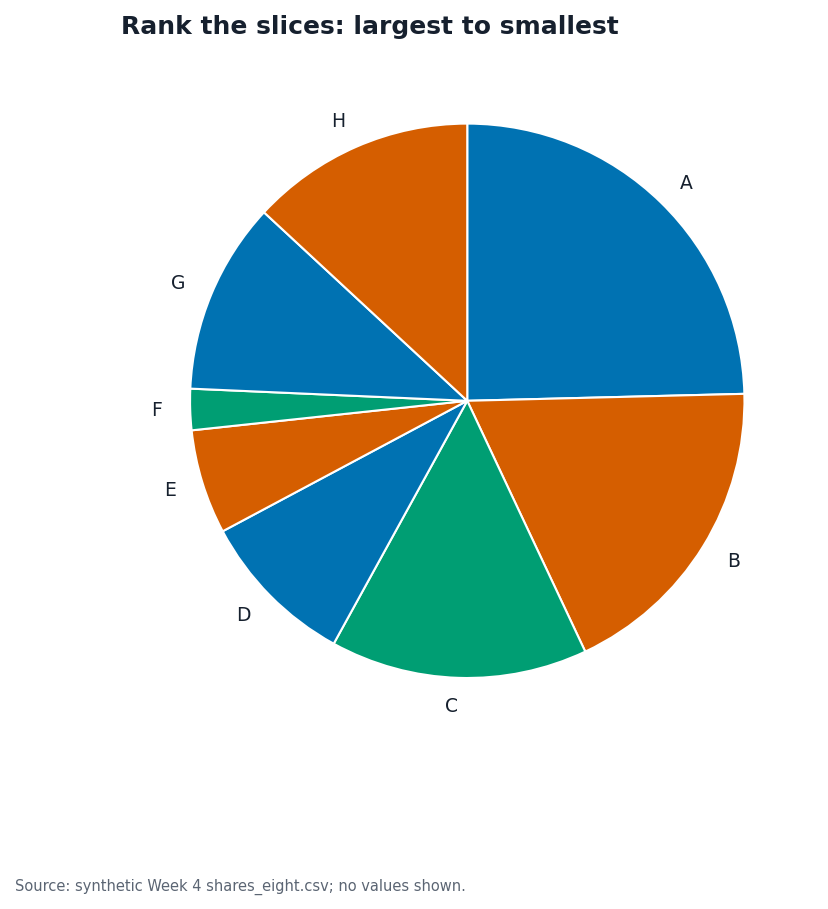

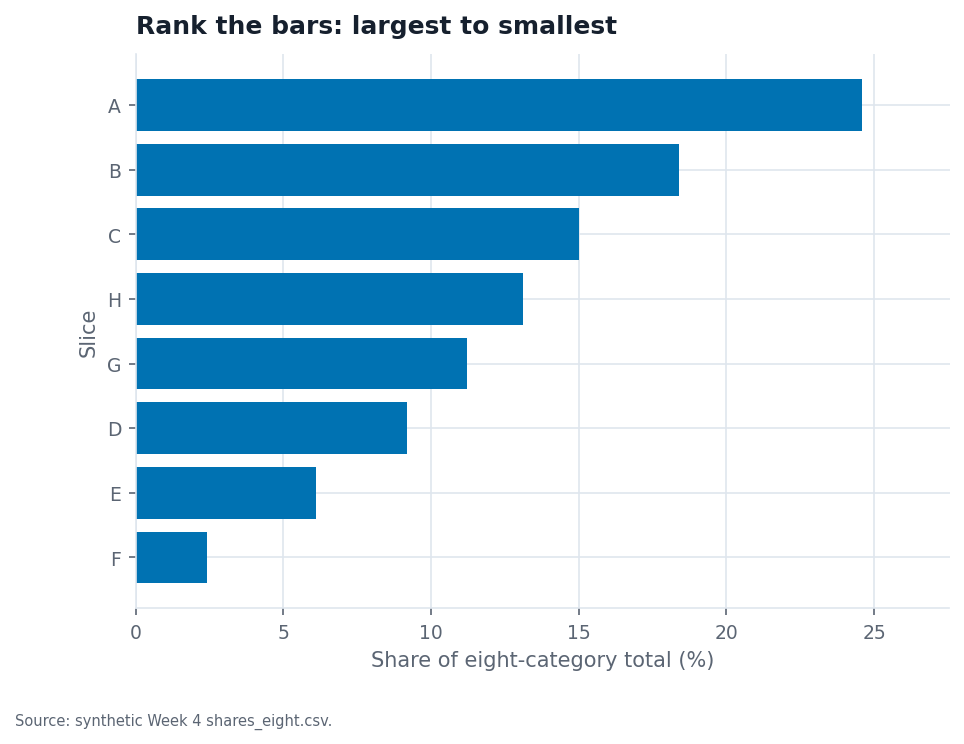

Stimuli saved: D:\7_Semester\data-visualization\week4\taskC_stimuli\pie_ranking.png and D:\7_Semester\data-visualization\week4\taskC_stimuli\bars_ranking.png


In [2]:
from pathlib import Path
from tslib import save_fig

stimulus_dir = WEEK4_DIR / "taskC_stimuli"
stimulus_dir.mkdir(exist_ok=True)
pie_path = stimulus_dir / "pie_ranking.png"
bar_path = stimulus_dir / "bars_ranking.png"

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(shares["share_pct"], labels=shares["slice"], startangle=90,
       counterclock=False, colors=(PALETTE["series"] * 3)[:len(shares)],
       wedgeprops={"edgecolor": "white", "linewidth": 1})
ax.set_title("Rank the slices: largest to smallest")
save_fig(fig, pie_path, note="Source: synthetic Week 4 shares_eight.csv; no values shown.")
plt.show()

ranked = shares.sort_values("share_pct", ascending=True)
fig, ax = plt.subplots(figsize=(7, 4.8))
ax.barh(ranked["slice"], ranked["share_pct"], color=PALETTE["series"][0])
ax.set(title="Rank the bars: largest to smallest", xlabel="Share of eight-category total (%)",
       ylabel="Slice")
ax.set_xlim(0, ranked["share_pct"].max() * 1.12)
save_fig(fig, bar_path, note="Source: synthetic Week 4 shares_eight.csv.")
plt.show()
print("Stimuli saved:", pie_path, "and", bar_path)

## Run the task with one real reader

1. Invite one consenting reader who has not seen the answer key; explain
   they are ranking shares, not testing their ability.
2. For each stimulus, show the image and ask for A–H, largest first. Do not
   disclose values or coach them. The program times from display through
   their typed order.
3. Record the reader's order and seconds. A single reader is descriptive
   only: it cannot establish a population-level perceptual effect.

**Run the following cell manually in front of the reader.** It will wait for
their two answers; it has intentionally not been run by the notebook author.

In [3]:
from time import perf_counter
from IPython.display import Image, display

results_path = WEEK4_DIR / "pie_ranking_results.csv"
if results_path.exists() and results_path.stat().st_size:
    results = pd.read_csv(results_path).to_dict(orient="records")
    stimuli = {str(row["stimulus"]) for row in results}
    if stimuli != {"pie", "bars"} or len(results) != 2:
        raise ValueError("Results CSV must have exactly one pie and one bars response.")
    print("Loaded the real-reader results already recorded in", results_path)
else:
    reader = input("Reader code/name (with their consent): ").strip()
    results = []
    for kind, image_path in [("pie", pie_path), ("bars", bar_path)]:
        print(f"\nStimulus: {kind}. Type the slice letters, largest first (for example A,H,C,...).")
        started = perf_counter()
        display(Image(filename=str(image_path)))
        while True:
            order = input("Reader's A?H order: ").strip().upper().replace(" ", "").replace(",", "")
            if len(order) == 8 and set(order) == set("ABCDEFGH"):
                break
            print("Please enter each letter A?H exactly once; timing continues.")
        seconds = perf_counter() - started
        results.append({"reader": reader, "stimulus": kind, "order": order, "seconds": seconds})
    pd.DataFrame(results).to_csv(results_path, index=False)
    print("Saved genuine reader responses to", results_path)

Loaded the real-reader results already recorded in D:\7_Semester\data-visualization\week4\pie_ranking_results.csv


## Score the recorded reader (run only after collecting responses)

In [4]:
results_path = WEEK4_DIR / "pie_ranking_results.csv"
if not results_path.exists() or results_path.stat().st_size == 0:
    print("Pending: no real-reader results have been recorded. No outcome is claimed.")
else:
    observed = pd.read_csv(results_path)
    truth = "".join(shares.sort_values("share_pct", ascending=False)["slice"].tolist())
    print("True order:", truth)
    scored = []
    for _, row in observed.iterrows():
        order = str(row["order"]).replace(" ", "").replace(",", "").upper()
        if len(order) != 8 or set(order) != set("ABCDEFGH"):
            raise ValueError(f"Invalid ranking for {row['stimulus']}: enter each A–H exactly once.")
        wrong_positions = [i + 1 for i, (actual, expected) in
                           enumerate(zip(order, truth)) if actual != expected]
        scored.append({"reader": row["reader"], "stimulus": row["stimulus"],
                       "order": order, "seconds": row["seconds"],
                       "wrong_positions": wrong_positions,
                       "wrong_letters_count": len(wrong_positions)})
    display(pd.DataFrame(scored))
    print("Compare the errors with positions 3–7; one reader and two stimuli "
          "cannot support a general claim.")

True order: ABCHGDEF


,reader,stimulus,order,seconds,wrong_positions,wrong_letters_count
0,1256,pie,ABCDEFGH,5,"[4, 5, 6, 7, 8]",5
1,1256,bars,ABCDEFGH,5,"[4, 5, 6, 7, 8]",5


Compare the errors with positions 3–7; one reader and two stimuli cannot support a general claim.


## Pie rule

Use a pie only when the parts are mutually exclusive and collectively form a
meaningful whole **and** the question is about share; otherwise use a bar
chart. Even when a pie is legal, use bars when precise ranking is the task.

**Reader status:** pending until a real reader completes both trials.
Do not report fabricated response orders or timings.